# Exploration Rats Analysis
O notebook para a análise dos dados de exploração de ratos 🐀. O notebook contém código para pré-processamento de dados, visualização e análise estatística do conjunto de dados de exploração de ratos.

> Esse estudo está sendo feito em colaboração com o Laboratório de Estudos em Memória e Cognição ([LEMCOG](https://sites.google.com/academico.ufpb.br/lemcog/)) da Universidade Federal da Paraíba (UFPB).

# 0. Leitura, imports e parâmetros.

In [1]:
import re
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Aquisição (Intan)
FS_ORIGINAL = 25_000   # Hz — frequência de amostragem
N_CANAIS    = 16

# Caminhos relativos à pasta onde está o notebook — ajuste se necessário
CSV_PATH    = Path('../data/R8_ANNOTATION.csv')
DADOS_DIR   = Path('../data/R8')    # contém REMOD*, D25/, D50/, D75/ e NOR/
CODIGO_DIR  = Path('..')            # pasta onde está o read_intan_data.py

df = pd.read_excel("../data/ALL_ANNOTATIONS.xlsx", sheet_name="R8")
df.to_csv(CSV_PATH, index=False) # Exportando para CSV apenas o sheet R8 (meu rato 🧀)

In [2]:
df = pd.read_csv(CSV_PATH, sep=",") 
df.head(15)

,Rato,Data,Objeto 1,Objeto 2,Condição,Sessão,Tipo,acontencimento,Sono_pre,Sono_pos
0,R8,08.11.2024,x,x,NOR,A1,Amostra,NaN,NaN,NaN
1,R8,08.11.2024,x,x,NOR,A2,Amostra,NaN,NaN,NaN
2,R8,08.11.2024,x,x,NOR,A3,Amostra,NaN,NaN,NaN
3,R8,08.11.2024,x,x,NOR,A4,Amostra,Signal ruim,NaN,NaN
4,R8,08.11.2024,novo,familiar,NOR,T1,Teste,NaN,NaN,NaN
5,R8,08.11.2024,novo,familiar,NOR,T2,Teste,NaN,NaN,NaN
6,R8,08.11.2024,familiar,novo,NOR,T3,Teste,TROCOU OBJETOS,NaN,NaN
7,R8,08.11.2024,familiar,novo,NOR,T4,Teste,NaN,NaN,NaN
8,R8,10.11.2024,x,x,0.25,A1,Amostra,signal com ruido,NaN,NaN
9,R8,10.11.2024,x,x,0.25,A2,Amostra,sem registro eletro,NaN,NaN


## 1 — Anotações: normalizar as colunas-chave

O nome do arquivo `.int` não traz os comentários do experimento (ex.: "sem registro eletro"). Eles estão só no CSV. Para ligar os dois lados precisamos de uma **chave** em comum, escrita sempre do mesmo jeito, por exemplo `R8_0.25_T1`.

Por isso as três colunas que formam a chave são padronizadas (sem espaços sobrando, em maiúsculas), e as células vazias de comentário viram texto vazio.

In [3]:
df_anot = pd.read_csv(CSV_PATH, sep=',')

df_anot['Rato']     = df_anot['Rato'].astype(str).str.strip().str.upper()
df_anot['Condição'] = df_anot['Condição'].astype(str).str.strip().str.upper()   # 'NOR', '0.25', '0.5', '0.75'
df_anot['Sessão']   = df_anot['Sessão'].astype(str).str.strip().str.upper()
df_anot['acontencimento'] = df_anot['acontencimento'].fillna('').str.strip()

# Chave que liga o CSV aos arquivos .int
df_anot['_key'] = df_anot['Rato'] + '_' + df_anot['Condição'] + '_' + df_anot['Sessão']

print(f'Anotações carregadas: {len(df_anot)} linhas, {df_anot["Rato"].nunique()} rato(s)')
print(df_anot[['_key', 'Tipo', 'acontencimento']].head(10).to_string(index=False))
print('\nChaves únicas:', df_anot['_key'].nunique(), 'de', len(df_anot))

Anotações carregadas: 32 linhas, 1 rato(s)
      _key    Tipo      acontencimento
 R8_NOR_A1 Amostra                    
 R8_NOR_A2 Amostra                    
 R8_NOR_A3 Amostra                    
 R8_NOR_A4 Amostra         Signal ruim
 R8_NOR_T1   Teste                    
 R8_NOR_T2   Teste                    
 R8_NOR_T3   Teste      TROCOU OBJETOS
 R8_NOR_T4   Teste                    
R8_0.25_A1 Amostra    signal com ruido
R8_0.25_A2 Amostra sem registro eletro

Chaves únicas: 32 de 32


## 1.2 — Arquivos `.int` e parser de nomes

A chave do CSV e a do arquivo precisam ser **escritas igual**, mas os nomes dos arquivos têm outro formato e informações a mais (data e hora). O parser extrai `(rato, condição, sessão)` do nome:

| Nome | Resultado |
|---|---|
| `R8D25ST1_241110_131445` | `R8`, `0.25`, `T1` (note o `S` extra no D25) |
| `R8D75A3_...` | `R8`, `0.75`, `A3` |
| `R8NORT2_...` | `R8`, `NOR`, `T2` |
| `R8D25SONOPRE_...` | `R8`, `0.25`, `SONO_PRE` |
| `R8NORSONOPOS_...` | `R8`, `NOR`, `SONO_POS` |
| `SONOPRENOR_...` | sem rato no nome, `NOR`, `SONO_PRE` (o rato vem da pasta) |

`re.fullmatch` exige que o texto **inteiro** case com o padrão. Os parênteses marcam o que queremos guardar. Arquivos que não casam com nenhum padrão (ex.: `REMOD_...`) retornam `None`.

In [4]:
# Só .int de verdade (ignora downloads incompletos como '.int....part')
arquivos_int = sorted(p for p in DADOS_DIR.rglob('*') if p.suffix.lower() == '.int')
print('Arquivos .int encontrados:', len(arquivos_int))

Arquivos .int encontrados: 61


In [5]:
def rato_pela_pasta(path):
    """Quando o nome não traz o rato (SONOPRENOR_...), usa o nome da pasta (.../R8/...)."""
    for parte in reversed(path.parent.parts):
        if re.fullmatch(r'R\d+', parte.strip().upper()):
            return parte.strip().upper()
    return None


def parse_nome_arquivo(stem):
    """Extrai (rato, condição, sessão) do nome do arquivo. Retorna (None, None, None) se não reconhecer."""
    base = stem.strip().upper().split('_')[0]   # 'R8D25ST1_241110_131445' -> 'R8D25ST1'

    # Sessões A (amostra) e T (teste) com dose: R8D25SA1, R8D75T2
    m = re.fullmatch(r'(R\d+)D(\d+)S?([AT]\d+)', base)
    if m:
        rato, dose, sessao = m.groups()
        return rato, str(int(dose) / 100), sessao

    # Sessões A e T da condição NOR: R8NORA1, R8NORT3
    m = re.fullmatch(r'(R\d+)NOR([AT]\d+)', base)
    if m:
        rato, sessao = m.groups()
        return rato, 'NOR', sessao

    # Sono com dose: R8D25SONOPRE
    m = re.fullmatch(r'(R\d+)D(\d+)SONO(PRE|POS)', base)
    if m:
        rato, dose, fase = m.groups()
        return rato, str(int(dose) / 100), 'SONO_' + fase

    # Sono NOR com rato no nome: R8NORSONOPOS
    m = re.fullmatch(r'(R\d+)NORSONO(PRE|POS)', base)
    if m:
        rato, fase = m.groups()
        return rato, 'NOR', 'SONO_' + fase

    # Sono NOR sem rato no nome: SONOPRENOR / SONOPOSNOR
    m = re.fullmatch(r'SONO(PRE|POS)NOR', base)
    if m:
        return None, 'NOR', 'SONO_' + m.group(1)

    return None, None, None

In [6]:
# Conferência: nome do arquivo -> chave
for p in arquivos_int:
    rato, cond, sessao = parse_nome_arquivo(p.stem)
    rato = rato or rato_pela_pasta(p)
    chave = f'{rato}_{cond}_{sessao}' if cond else None
    print(f'{p.stem:35} -> {chave}')

R8D25SA1_241110_130836              -> R8_0.25_A1
R8D25SA3_241110_133750              -> R8_0.25_A3
R8D25SA4_241110_135622              -> R8_0.25_A4
R8D25SONOPOS_241110_140954          -> R8_0.25_SONO_POS
R8D25SONOPOS_241110_142954          -> R8_0.25_SONO_POS
R8D25SONOPOS_241110_144954          -> R8_0.25_SONO_POS
R8D25SONOPOS_241110_151014          -> R8_0.25_SONO_POS
R8D25SONOPRE_241110_111148          -> R8_0.25_SONO_PRE
R8D25SONOPRE_241110_113149          -> R8_0.25_SONO_PRE
R8D25SONOPRE_241110_115149          -> R8_0.25_SONO_PRE
R8D25SONOPRE_241110_121149          -> R8_0.25_SONO_PRE
R8D25SONOPRE_241110_123149          -> R8_0.25_SONO_PRE
R8D25SONOPRE_241110_125149          -> R8_0.25_SONO_PRE
R8D25ST1_241110_131445              -> R8_0.25_T1
R8D25ST2_241110_132933              -> R8_0.25_T2
R8D25ST3_241110_134540              -> R8_0.25_T3
R8D25ST4_241110_140423              -> R8_0.25_T4
R8D50SONOPOS_241115_103314          -> R8_0.5_SONO_POS
R8D50SONOPOS_241115_105314         

### Tabela de arquivos

A lista de caminhos vira uma tabela (uma linha por arquivo), com a chave `_key` em uma coluna. Arquivos que o parser não reconheceu ficam sem chave.

In [7]:
registros = []
for p in arquivos_int:
    rato, cond, sessao = parse_nome_arquivo(p.stem)
    registros.append({
        'path': p,
        'stem': p.stem,
        'rato': rato or rato_pela_pasta(p),
        'condicao': cond,
        'trial': sessao,
    })

df_arquivos = pd.DataFrame(registros)


def montar_chave(linha):
    if pd.isna(linha['condicao']):          # arquivo que o parser não reconheceu
        return None
    return f"{linha['rato']}_{linha['condicao']}_{linha['trial']}"


df_arquivos['_key'] = df_arquivos.apply(montar_chave, axis=1)

print('Total de arquivos:', len(df_arquivos))
print('Nomes repetidos  :', df_arquivos['stem'].duplicated().sum())
print('Sem chave        :', df_arquivos['_key'].isna().sum())
print()
print(df_arquivos.groupby('_key').size().to_string())

Total de arquivos: 61
Nomes repetidos  : 0
Sem chave        : 2

_key
R8_0.25_A1          1
R8_0.25_A3          1
R8_0.25_A4          1
R8_0.25_SONO_POS    4
R8_0.25_SONO_PRE    6
R8_0.25_T1          1
R8_0.25_T2          1
R8_0.25_T3          1
R8_0.25_T4          1
R8_0.5_SONO_POS     3
R8_0.75_A1          1
R8_0.75_A2          1
R8_0.75_A3          1
R8_0.75_A4          1
R8_0.75_SONO_POS    4
R8_0.75_SONO_PRE    7
R8_0.75_T1          1
R8_0.75_T2          1
R8_0.75_T3          1
R8_0.75_T4          1
R8_NOR_A1           1
R8_NOR_A2           1
R8_NOR_A3           1
R8_NOR_A4           1
R8_NOR_SONO_POS     5
R8_NOR_SONO_PRE     7
R8_NOR_T1           1
R8_NOR_T2           1
R8_NOR_T3           1
R8_NOR_T4           1


## 1.3 — Join arquivos × anotações

Cada arquivo busca no CSV a linha com a mesma `_key` e traz os comentários dela.

- `how='left'` mantém **todos** os arquivos, mesmo os sem par no CSV (sono e `REMOD`).
- `drop_duplicates('_key')` evita que uma chave repetida no CSV duplique arquivos.
- `indicator=True` cria a coluna `_merge` (`both` = achou par, `left_only` = não achou).

In [8]:
colunas_csv = ['_key', 'Tipo', 'acontencimento', 'Sono_pre', 'Sono_pos']

# Permite rodar a célula mais de uma vez sem criar colunas duplicadas (_x, _y)
df_arquivos = df_arquivos.drop(columns=[c for c in colunas_csv[1:] + ['_merge'] if c in df_arquivos.columns])

df_arquivos = df_arquivos.merge(
    df_anot[colunas_csv].drop_duplicates('_key'),
    on='_key',
    how='left',
    indicator=True,
)

df_arquivos['acontencimento'] = df_arquivos['acontencimento'].fillna('')

print(df_arquivos['_merge'].value_counts().to_string())

print('\nArquivos com comentário:')
print(df_arquivos[df_arquivos['acontencimento'] != '']
      [['stem', 'acontencimento']].to_string(index=False))

# Lado contrário: linhas do CSV que não encontraram nenhum arquivo
sem_arquivo = df_anot[~df_anot['_key'].isin(df_arquivos['_key'])]
print(f'\nAnotações sem arquivo .int: {len(sem_arquivo)}')
print(sem_arquivo[['_key', 'acontencimento']].to_string(index=False))

_merge
left_only     38
both          23
right_only     0

Arquivos com comentário:
                  stem               acontencimento
R8D25SA1_241110_130836             signal com ruido
 R8D75A4_241112_132536               demorou a sair
 R8D75T3_241112_131327 não explorou, demorou a sair
 R8NORA4_241108_125038                  Signal ruim
 R8NORT3_241108_124108               TROCOU OBJETOS

Anotações sem arquivo .int: 9
      _key      acontencimento
R8_0.25_A2 sem registro eletro
 R8_0.5_A1                 KD?
 R8_0.5_A2                 KD?
 R8_0.5_A3                 KD?
 R8_0.5_A4                 KD?
 R8_0.5_T1                 KD?
 R8_0.5_T2                 KD?
 R8_0.5_T3                 KD?
 R8_0.5_T4                 KD?


## 2 — Remoção dos arquivos com comentário de falha

Critério: comentário contendo `falha`, `cancelar`/`cancelada` ou `sem registro`.

Comentários de **ruído** ("signal ruim", "signal com ruido") **não** descartam a sessão aqui: a detecção de ruído fica com o SPARQ, que mede a fração de sinal ruidoso. Comentários de comportamento ("demorou a sair", "TROCOU OBJETOS") também não são falha de registro.

O filtro remove linhas da **tabela**, não apaga arquivos do disco.

In [9]:
PADRAO_FALHA = 'falha|cancelar|cancelada|sem registro'

n_antes = len(df_arquivos)

mask_falha = df_arquivos['acontencimento'].str.lower().str.contains(PADRAO_FALHA, na=False)

df_falhas = df_arquivos[mask_falha]
print('Arquivos descartados por falha:', len(df_falhas))
print(df_falhas[['stem', 'acontencimento']].to_string(index=False))

df_arquivos = df_arquivos[~mask_falha].reset_index(drop=True)
print('Restantes:', len(df_arquivos), '| removidos:', n_antes - len(df_arquivos))

Arquivos descartados por falha: 0
Empty DataFrame
Columns: [stem, acontencimento]
Index: []
Restantes: 61 | removidos: 0


In [10]:
# Conferência: o mesmo padrão aplicado a todas as anotações do CSV
m = df_anot['acontencimento'].str.lower().str.contains(PADRAO_FALHA, na=False)
print(df_anot.loc[m, ['_key', 'acontencimento']].to_string(index=False))

      _key      acontencimento
R8_0.25_A2 sem registro eletro


## 3 — Leitura e inspeção de um arquivo `.int`

Antes de processar todos os arquivos, lemos **um** e olhamos o sinal. Se algo estiver errado na leitura, é melhor descobrir aqui.

- `read_intan_data` devolve os canais que estavam **ligados** na gravação e uma matriz `[canais ativos × amostras]`.
- `carregar_intan` reposiciona cada canal na sua linha física (canal 5 → linha 5) e deixa **zeros** nos canais desligados. Assim a matriz tem sempre 16 linhas e o canal N está sempre na mesma linha.
- Os valores ficam em `float32` para economizar memória (2 min × 16 canais × 25 kHz ≈ 190 MB).

In [ ]:
sys.path.insert(0, str(CODIGO_DIR))
from utils.read_intan_data import read_intan_data

def carregar_intan(path):
    """Lê o .int e posiciona cada canal ativo na sua linha física (canal N -> linha N-1).
    Canais inativos ficam zerados. Retorna (amps [N_CANAIS, N_amostras], canais_ativos)."""
    _, canais_ativos, data_neural, _ = read_intan_data(str(path))
    data_neural = np.asarray(data_neural, dtype=np.float32)

    amps = np.zeros((N_CANAIS, data_neural.shape[1]), dtype=np.float32)
    for pos, canal_fisico in enumerate(canais_ativos):
        if 1 <= canal_fisico <= N_CANAIS:
            amps[canal_fisico - 1] = data_neural[pos]
    return amps, canais_ativos

### 3.1 — Ler um arquivo e resumir os canais

In [12]:
ARQUIVO_TESTE = 'R8NORA1'   # início do nome (stem) do arquivo a inspecionar

linha = df_arquivos[df_arquivos['stem'].str.startswith(ARQUIVO_TESTE)].iloc[0]
print('Arquivo :', linha['stem'])

amps, canais_ativos = carregar_intan(linha['path'])

print('Formato :', amps.shape, '(canais x amostras)')
print('Duração : %.1f s' % (amps.shape[1] / FS_ORIGINAL))
print('Ativos  :', [int(c) for c in canais_ativos])
print('NaN     :', int(np.isnan(amps).sum()))

resumo = pd.DataFrame({
    'canal':  np.arange(1, N_CANAIS + 1),
    'ativo':  [c in canais_ativos for c in range(1, N_CANAIS + 1)],
    'media':  amps.mean(axis=1),
    'desvio': amps.std(axis=1),
    'min':    amps.min(axis=1),
    'max':    amps.max(axis=1),
}).round(2)
print(resumo.to_string(index=False))

Arquivo : R8NORA1_241108_120414

Data file contains 200.91 seconds of data from 14 amplifier channels.
Channels: 1 2 3 4 5 6 7 9 10 11 12 14 15 16
Formato : (16, 5022750) (canais x amostras)
Duração : 200.9 s
Ativos  : [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 16]
NaN     : 0
 canal  ativo  media     desvio         min        max
     1   True  -0.05 124.940002 -621.299988 615.359985
     2   True  -0.08 112.669998 -630.530029 615.010010
     3   True  -0.08  47.400002 -683.489990 692.390015
     4   True  -0.08  47.820000 -688.270020 685.130005
     5   True  -0.07  47.959999 -696.690002 695.969971
     6   True  -0.08  47.750000 -682.820007 676.390015
     7   True  -0.08  47.630001 -673.039978 625.320007
     8  False   0.00   0.000000    0.000000   0.000000
     9   True  -0.08 123.519997 -627.609985 606.330017
    10   True  -0.11 125.800003 -622.929993 605.099976
    11   True  -0.10 133.619995 -625.380005 618.780029
    12   True  -0.09 147.880005 -633.640015 622.580017
    1

### 3.2 — Olhar o sinal

Primeiros 3 segundos de três canais. Uma oscilação regular e "grossa" por cima do sinal é provavelmente a interferência de 60 Hz, que o notch vai remover mais adiante.

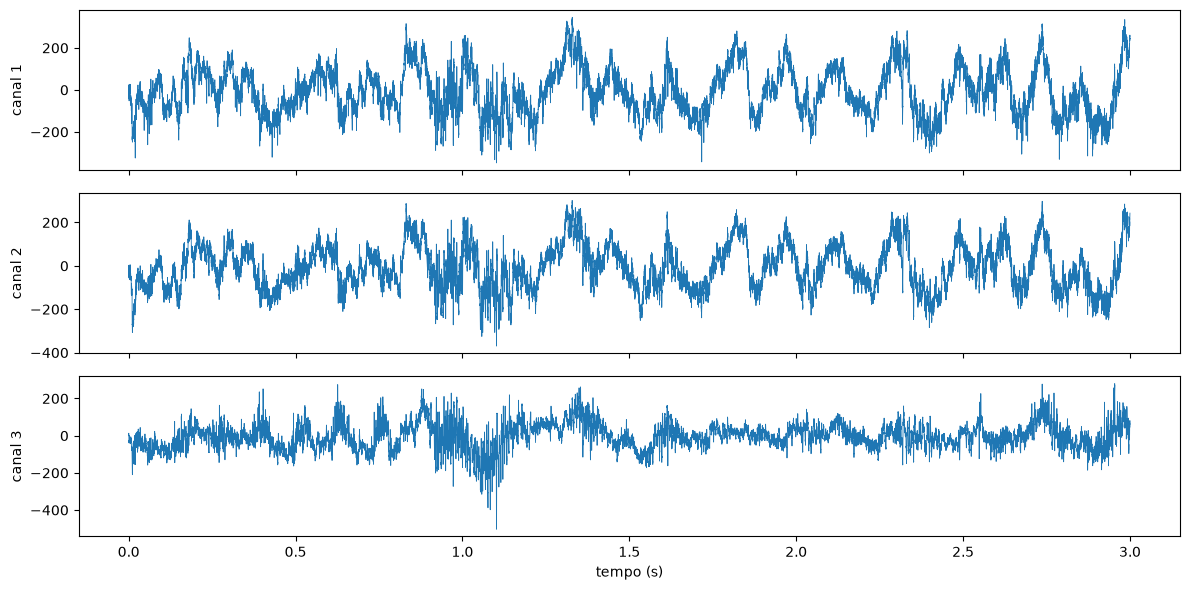

In [13]:
n = min(3 * FS_ORIGINAL, amps.shape[1])
t = np.arange(n) / FS_ORIGINAL

fig, eixos = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, canal in zip(eixos, [1, 2, 3]):
    ax.plot(t, amps[canal - 1, :n], lw=0.6)
    ax.set_ylabel(f'canal {canal}')
eixos[-1].set_xlabel('tempo (s)')
plt.tight_layout()
plt.show()

## 4 — Detecção de ruído com o SPARQ

O [SPARQ](https://github.com/lafise-ufrn/SPARQ) roda no MATLAB. Ele **não** identifica canais ruins: a partir de um trecho limpo que você marca como referência, calcula limiares e gera uma `noiseMask`, um vetor de 0 e 1 (1 = ruído) com um valor por amostra, comum a todos os canais.

**Fluxo**

1. O Python exporta cada sessão para um `.mat` com `LFP` (canais × amostras) e `fs`, a **1 kHz**. A frequência é reduzida porque os parâmetros do SPARQ são contados em amostras.
2. No MATLAB, o SPARQ abre esses `.mat`. Para cada sessão, marca-se o início e o fim de um trecho limpo e salva-se o resultado (`*_clean.mat`).
3. O Python lê a `noiseMask`, expande para 25 kHz e calcula a fração ruidosa. Se passar de `LIMIAR_RUIDO`, a sessão é descartada; senão, as amostras ruidosas viram `NaN` (depois do notch, ver seção 5).

**Atenção:** os parâmetros do SPARQ (limiar, canais simultâneos, canais excluídos...) devem ser os **mesmos para todos os ratos** do grupo. No `R8NORA1` os canais 8 e 13 aparecem planos (não gravados), e o campo "Canais excluídos" estava vazio: confirmar o padrão do laboratório.

### 4.1 — Exportar uma sessão (teste com o arquivo da seção 3)

In [ ]:
destino = exportar_para_sparq(amps, FS_ORIGINAL, FS_SPARQ,
                              SPARQ_INPUT_DIR, linha['rato'], linha['stem'])
print('Salvo em:', destino)

# conferência: lê de volta o que foi gravado
mat = sio.loadmat(destino)
print('LFP:', mat['LFP'].shape, '| fs:', float(mat['fs'].squeeze()))
print('Duração: %.1f s' % (mat['LFP'].shape[1] / float(mat['fs'].squeeze())))

### 4.2 — Abrir o SPARQ e marcar a referência (no MATLAB)

Esta etapa é **manual**. Rode a célula abaixo, copie os dois comandos e cole na *Command Window* do MATLAB (R2021a ou mais novo). Depois, na janela do SPARQ:

1. **Carregar sessões**: as sessões do `SPARQ_input` aparecem na lista.
2. Selecione a sessão e **clique no início e depois no fim de um trecho limpo** do sinal (a referência).
3. Confira os gráficos e o percentual de sinal preservado.
4. **Salvar resultado desta sessão** (ou "de todas as sessões"). O arquivo `*_clean.mat` vai para `SPARQ_input/SPARQ_results/`.

In [ ]:
def imprimir_comandos_matlab():
    """Imprime os dois comandos para colar na Command Window do MATLAB."""
    print(f"addpath(genpath('{SPARQ_REPO.resolve()}'));")
    print(f'app = SPARQ_GUI("DataFolder", "{SPARQ_INPUT_DIR.resolve()}");')

imprimir_comandos_matlab()